# Data Transformation in Pandas:

# Data Manipulation and Transformation :

    o  Methods for reshaping and transforming data, including groupby() and pivot_table( / crosstab()
    o  Demonstrate how to apply functions to data using apply() and map(). 
    o  Explore merging(join) and concatenating DataFrames.(union)
    -- Understanding about imp methods like --> resetindex() / size() / fill_value() / slicing on Date(str) / regex() -- by using re.sub Module

In [ ]:
# Data manipulation and transformation in Pandas are essential techniques for analyzing and preparing data. 
In this section, we will cover methods for reshaping, grouping, transforming, applying functions to data, and combining multiple DataFrames. 

# 1. Reshaping and Transforming Data

# groupby() for Grouping Data:
    
    -- The groupby() method in Pandas is a powerful tool to group data based on one or more columns. 
    -- It can be followed by aggregation functions such as sum(), mean(), or count() to summarize data.

In [36]:
# Data Transformation in Pandas:
# Example: Grouping by a Column:

import pandas as pd

# Sample DataFrame
data = {
    'Name': ['AK', 'BK', 'CK', 'AK', 'BK', 'CK'],
    'City': ['New York', 'Los Angeles', 'Chicago', 'Chicago', 'New York', 'Los Angeles'],
    'Age': [24, 27, 22, 32, 29, 28],
    'Salary': [50000, 60000, 55000, 80000, 75000, 72000]
}
df = pd.DataFrame(data)

print(df)

# Group by 'Name' and calculate the average salary for each person
Name_grouped = df.groupby('Name')['Salary'].mean()         # grouped = df.groupby('Name')['Salary'].sum()
print(Name_grouped)

# Group by 'City' and calculate the sum salary for each person
City_grouped = df.groupby('City')['Salary'].sum()         # grouped = df.groupby('Name')['Salary'].sum()
print(City_grouped)

# Group by 'City' and calculate total salary, sorted descending
City_grouped = df.groupby('City')['Salary'].sum().sort_values(ascending=False)
print("\nTotal Salary by City (sorted high to low):\n", City_grouped)

# Sorting Options:
# sort_values(ascending=False): Sorts from highest to lowest.
# sort_values(ascending=True): Sorts from lowest to highest.

  Name         City  Age  Salary
0   AK     New York   24   50000
1   BK  Los Angeles   27   60000
2   CK      Chicago   22   55000
3   AK      Chicago   32   80000
4   BK     New York   29   75000
5   CK  Los Angeles   28   72000
Name
AK    65000.0
BK    67500.0
CK    63500.0
Name: Salary, dtype: float64
City
Chicago        135000
Los Angeles    132000
New York       125000
Name: Salary, dtype: int64

Total Salary by City (sorted high to low):
 City
Chicago        135000
Los Angeles    132000
New York       125000
Name: Salary, dtype: int64


In [38]:
# Aggregating Data with groupby()
# You can apply multiple aggregation functions to grouped data using the agg() method.
# Group by 'City' and get mean and sum of 'Age' and 'Salary'

print(df)

grouped_agg = df.groupby('City').agg({'Age': 'mean','Salary': 'sum'})
print(grouped_agg)

  Name         City  Age  Salary
0   AK     New York   24   50000
1   BK  Los Angeles   27   60000
2   CK      Chicago   22   55000
3   AK      Chicago   32   80000
4   BK     New York   29   75000
5   CK  Los Angeles   28   72000
              Age  Salary
City                     
Chicago      27.0  135000
Los Angeles  27.5  132000
New York     26.5  125000


In [40]:
# Example: Applying a Function to Each Column

import pandas as pd

# Sample DataFrame
data = {
    'Name': ['AK', 'BK', 'CK', 'Alice', 'BK', 'Ck'],
    'City': ['New York', 'Los Angeles', 'Chicago', 'Chicago', 'New York', 'Los Angeles'],
    'Age': [24, 27, 22, 32, 29, 28],
    'Salary': [50000, 60000, 55000, 80000, 75000, 72000]
}
df = pd.DataFrame(data)

print(df)

# Apply a function only for 1 column - Age
numeric_column = df[['Age']].apply(sum)
print(numeric_column)

# Apply a function to each column to get the sum of each column
numeric_column_sums = df.select_dtypes(include='number').apply(sum)       #column_sums = df.apply(sum) 
print(numeric_column_sums)

    Name         City  Age  Salary
0     AK     New York   24   50000
1     BK  Los Angeles   27   60000
2     CK      Chicago   22   55000
3  Alice      Chicago   32   80000
4     BK     New York   29   75000
5     Ck  Los Angeles   28   72000
Age    162
dtype: int64
Age          162
Salary    392000
dtype: int64


In [36]:
# Example of filtering products:

import pandas as pd

# Sample product data
data = {
    'ProductID': [1, 2, 3, 4, 5],
    'ProductName': ['Laptop', 'Mouse', 'Keyboard', 'Monitor', 'Headset'],
    'Category': ['Electronics', 'Accessories', 'Accessories', 'Electronics', 'Accessories'],
    'Price': [70000, 500, 1500, 12000, 2000],
    'InStock': [True, True, False, True, False]
}

df = pd.DataFrame(data)
print("Original Product List:\n", df)

Original Product List:
    ProductID ProductName     Category  Price  InStock
0          1      Laptop  Electronics  70000     True
1          2       Mouse  Accessories    500     True
2          3    Keyboard  Accessories   1500    False
3          4     Monitor  Electronics  12000     True
4          5     Headset  Accessories   2000    False


In [38]:
# Filter Products in "Accessories" Category

accessories_df = df[df['Category'] == 'Accessories']
print("\nAccessories:\n", accessories_df)


Accessories:
    ProductID ProductName     Category  Price  InStock
1          2       Mouse  Accessories    500     True
2          3    Keyboard  Accessories   1500    False
4          5     Headset  Accessories   2000    False


In [40]:
# Filter Products with Price > 5000

expensive_df = df[df['Price'] > 5000]
print("\nExpensive Products (Price > 5000):\n", expensive_df)


Expensive Products (Price > 5000):
    ProductID ProductName     Category  Price  InStock
0          1      Laptop  Electronics  70000     True
3          4     Monitor  Electronics  12000     True


In [7]:
# Filter Only Products In Stock:

in_stock_df = df[df['InStock'] == True]
print("\nIn-Stock Products:\n", in_stock_df)


In-Stock Products:
    ProductID ProductName     Category  Price  InStock
0          1      Laptop  Electronics  70000     True
1          2       Mouse  Accessories    500     True
3          4     Monitor  Electronics  12000     True


# Pivot Tables with pivot_table():
    The pivot_table() function is used to reshape data by creating a new table where you can specify rows,
    columns, and aggregation functions for data transformation.

In [42]:
# Example: Creating a Pivot Table

# Exmaple - 1:
import pandas as pd

# Sample DataFrame
data = {
    'Name': ['Alice', 'Bob', 'Charlie', 'Alice', 'Bob', 'Charlie'],
    'City': ['New York', 'Los Angeles', 'Chicago', 'Chicago', 'New York', 'Los Angeles'],
    'Age': [24, 27, 22, 32, 29, 28],
    'Salary': [50000, 60000, 55000, 80000, 75000, 72000]
}
df = pd.DataFrame(data)
print(df)

      Name         City  Age  Salary
0    Alice     New York   24   50000
1      Bob  Los Angeles   27   60000
2  Charlie      Chicago   22   55000
3    Alice      Chicago   32   80000
4      Bob     New York   29   75000
5  Charlie  Los Angeles   28   72000


In [44]:
# Create a pivot table that shows the average Salary by City and Name

pivot = df.pivot_table(values='Salary', index='City', columns='Name', aggfunc='mean')
print(pivot)

Name           Alice      Bob  Charlie
City                                  
Chicago      80000.0      NaN  55000.0
Los Angeles      NaN  60000.0  72000.0
New York     50000.0  75000.0      NaN


# What is crosstab() in Pandas?

    pd.crosstab() is used to create a cross-tabulation table between two or more categorical columns.

# In simple terms, it answers questions like:

    How many customers from each city bought each product category?
    How many male/female employees belong to each department?
    How many orders in each region have each delivery status?

It is similar to a PivotTable in Excel.

# Syntax: pd.crosstab(index, columns)
# Where:
    index → values shown as rows
    columns → values shown as columns

# Business Example — Retail Sales Analysis:

# Scenario: A retail company wants to understand:
# How many orders were placed for each Product Category from each City?

In [9]:
import pandas as pd

data = {
    "OrderID": [101, 102, 103, 104, 105, 106, 107, 108, 109, 110],
    "City": [
        "Chennai",
        "Bangalore",
        "Chennai",
        "Hyderabad",
        "Bangalore",
        "Chennai",
        "Hyderabad",
        "Bangalore",
        "Chennai",
        "Hyderabad"
    ],
    "Category": [
        "Electronics",
        "Clothing",
        "Clothing",
        "Electronics",
        "Electronics",
        "Electronics",
        "Clothing",
        "Clothing",
        "Electronics",
        "Clothing"
    ]
}

sales_df = pd.DataFrame(data)

print(sales_df)

   OrderID       City     Category
0      101    Chennai  Electronics
1      102  Bangalore     Clothing
2      103    Chennai     Clothing
3      104  Hyderabad  Electronics
4      105  Bangalore  Electronics
5      106    Chennai  Electronics
6      107  Hyderabad     Clothing
7      108  Bangalore     Clothing
8      109    Chennai  Electronics
9      110  Hyderabad     Clothing


In [ ]:
import pandas as pd

data = {
    "OrderID": [101, 102, 103, 104, 105, 106, 107, 108, 109, 110],
    "City": [
        "Chennai",
        "Bangalore",
        "Chennai",
        "Hyderabad",
        "Bangalore",
        "Chennai",
        "Hyderabad",
        "Bangalore",
        "Chennai",
        "Hyderabad"
    ],
    "Category": [
        "Electronics",
        "Clothing",
        "Clothing",
        "Electronics",
        "Electronics",
        "Electronics",
        "Clothing",
        "Clothing",
        "Electronics",
        "Clothing"
    ]
}

sales_df = pd.DataFrame(data)

print(sales_df)

In [38]:
# Create a Crosstab

result = pd.crosstab(
    sales_df["Category"],
    sales_df["City"]
)

print(result)

City         Bangalore  Chennai  Hyderabad
Category                                  
Clothing             1        1          1
Electronics          1        2          0


In [13]:
# Adding Totals with margins=True: we get Row Total / Column Total and Grand Total:
pd.crosstab(
    sales_df["City"],
    sales_df["Category"],
    margins=True
)

Category,Clothing,Electronics,All
City,,,
Bangalore,2,1,3
Chennai,1,3,4
Hyderabad,2,1,3
All,5,5,10


In [15]:
# Percentage Analysis Using normalize: What percentage of orders in each city belong to each category?

pd.crosstab(
    sales_df["City"],
    sales_df["Category"],
    normalize="index"
) * 100

Category,Clothing,Electronics
City,,
Bangalore,66.666667,33.333333
Chennai,25.000000,75.000000
Hyderabad,66.666667,33.333333


In [28]:
result = (
    pd.crosstab(
        sales_df["City"],
        sales_df["Category"],
        normalize="index"
    ) * 100
).round(2)

print(result)

Category   Clothing  Electronics
City                            
Bangalore     50.00        50.00
Chennai       33.33        66.67
Hyderabad      0.00       100.00


In [ ]:
# Crosstab with Aggregate Values: crosstab() can also calculate something other than counts

In [19]:
data = {
    "City": [
        "Chennai",
        "Bangalore",
        "Chennai",
        "Hyderabad",
        "Bangalore",
        "Chennai"
    ],

    "Category": [
        "Electronics",
        "Clothing",
        "Clothing",
        "Electronics",
        "Electronics",
        "Electronics"
    ],

    "SalesAmount": [
        50000,
        3000,
        5000,
        35000,
        40000,
        60000
    ]
}

sales_df = pd.DataFrame(data)
print(sales_df)

        City     Category  SalesAmount
0    Chennai  Electronics        50000
1  Bangalore     Clothing         3000
2    Chennai     Clothing         5000
3  Hyderabad  Electronics        35000
4  Bangalore  Electronics        40000
5    Chennai  Electronics        60000


In [23]:
# Total sales amount for each City and Category combination. we can change the columns view as well: Category -> City
# This changes crosstab() from a frequency table into an aggregated business report.

result = pd.crosstab(
    sales_df["City"],
    sales_df["Category"],
    values=sales_df["SalesAmount"],
    aggfunc="sum"
)

print(result)

City         Bangalore   Chennai  Hyderabad
Category                                   
Clothing        3000.0    5000.0        NaN
Electronics    40000.0  110000.0    35000.0


# Important           Parameters
#    Parameter	      Purpose
     index	          Defines rows
     columns	      Defines columns
     values	Column    whose values should be aggregated
     aggfunc	      Aggregation such as sum, mean, max
     margins=True	  Adds totals
     
     normalize=True	        Converts counts into proportions
     normalize="index"	    Row-wise percentages
     normalize="columns"	Column-wise percentages

In [32]:
import pandas as pd

data = {
    "City": [
        "Chennai",
        "Chennai",
        "Chennai",
        "Bangalore",
        "Bangalore",
        "Hyderabad"
    ],
    "Category": [
        "Electronics",
        "Electronics",
        "Clothing",
        "Electronics",
        "Clothing",
        "Clothing"
    ]
}

sales_df = pd.DataFrame(data)

In [34]:
print(
    pd.crosstab(
        sales_df["City"],
        sales_df["Category"]
    )
)

Category   Clothing  Electronics
City                            
Bangalore         1            1
Chennai           1            2
Hyderabad         1            0


In [40]:
# normalize=True = percentage of the grand total. This calculates each cell as a percentage of the entire dataset.
result = (
    pd.crosstab(
        sales_df["City"],
        sales_df["Category"],
        normalize=True
    ) * 100
).round(2)

print(result)

Category   Clothing  Electronics
City                            
Bangalore     16.67        16.67
Chennai       16.67        33.33
Hyderabad     16.67         0.00


In [42]:
# normalize="index" - This calculates row-wise percentages. Within each city, what percentage of orders belong to each category?
result = (
    pd.crosstab(
        sales_df["City"],
        sales_df["Category"],
        normalize="index"
    ) * 100
).round(2)

print(result)

Category   Clothing  Electronics
City                            
Bangalore     50.00        50.00
Chennai       33.33        66.67
Hyderabad    100.00         0.00


In [44]:
# normalize="columns" - This calculates column-wise percentages. For each product category, what percentage comes from each city?
result = (
    pd.crosstab(
        sales_df["City"],
        sales_df["Category"],
        normalize="columns"
    ) * 100
).round(2)

print(result)

Category   Clothing  Electronics
City                            
Bangalore     33.33        33.33
Chennai       33.33        66.67
Hyderabad     33.33         0.00


# Easy Comparison:
# Option	             Percentage calculated against	   Adds up to 100%
 normalize=True	         Entire DataFrame	               Whole table
 normalize="index"	     Each row	                       Each row
 normalize="columns"	 Each column	                   Each column

# Easy way to remember:
normalize=True
        ↓
Percentage of TOTAL

normalize="index"
        ↓
ROW percentage

normalize="columns"
        ↓
COLUMN percentage

# crosstab() vs value_counts()


In [ ]:
# Suppose you want only city-wise order counts:

sales_df["City"].value_counts()

# That gives one-dimensional frequency.

# But if you want: City versus Category
# use:

pd.crosstab(
    sales_df["City"],
    sales_df["Category"])

# So:  

    value_counts()
        ↓
    Frequency of one column

    crosstab()
        ↓
   Relationship/frequency between two or more columns

# Easy Way to Remember
# Think of:
pd.crosstab(A, B) as asking: "For every value of A, how many times does every value of B occur?"

# For example:

pd.crosstab(
    sales_df["City"],
    sales_df["Category"])

# means:
For every City, how many orders belong to each Category?
That is the most common business use of crosstab() in Pandas.

# What is pd.crosstab()?
    
    crosstab() is used to create a frequency table that shows how many times combinations of categories occur.
    It is very similar to a Pivot Table in Excel.

In [46]:
import pandas as pd

data = {
    "Department": ["HR", "HR", "IT", "IT", "IT", "Finance", "Finance"],
    "Gender": ["Male", "Female", "Male", "Female", "Male", "Female", "Male"]
}

df = pd.DataFrame(data)

print(df)

  Department  Gender
0         HR    Male
1         HR  Female
2         IT    Male
3         IT  Female
4         IT    Male
5    Finance  Female
6    Finance    Male


In [50]:
result = pd.crosstab(df["Department"], df["Gender"])  # Notice that Pandas arranged the columns alphabetically: Female and Male
print(result)

Gender      Female  Male
Department              
Finance          1     1
HR               1     1
IT               1     2


# Meaning:
    # Finance has 1 Female and 1 Male
    # HR has 1 Female and 1 Male
    # IT has 1 Female and 2 Males

In [48]:
# Making Columns Appear in a Specific Order:

import pandas as pd

data = {
    "Department": ["HR", "HR", "IT", "IT", "IT", "Finance", "Finance"],
    "Gender": ["Male", "Female", "Male", "Female", "Male", "Female", "Male"]
}
df = pd.DataFrame(data)

result = pd.crosstab(df["Department"], df["Gender"])

result = result.reindex(columns=["Male", "Female"],fill_value=0)

print(result)

# What does fill_value=0 do? Suppose there is no Female employee in Finance:

Gender      Female  Male
Department              
Finance          1     1
HR               1     1
IT               1     2


In [57]:
import pandas as pd

data = {
    "Section": ["Science", "Science", "Arts", "Arts",
                "Science", "Commerce", "Commerce"],
    "ReturnStatus": ["Returned", "Overdue", "Returned",
                     "Pending", "Returned", "Overdue", "Pending"]
}

df = pd.DataFrame(data)

result = pd.crosstab(df["Section"], df["ReturnStatus"])

print(result)

ReturnStatus  Overdue  Pending  Returned
Section                                 
Arts                0        1         1
Commerce            1        1         0
Science             1        0         2


In [ ]:
# Making Columns Appear in a Specific Order
# Suppose you always want:

In [59]:
result = pd.crosstab(df["Section"], df["ReturnStatus"])

result = result.reindex(columns=["Returned", "Pending", "Overdue","Other"],fill_value=0
)

print(result)

ReturnStatus  Returned  Pending  Overdue  Other
Section                                        
Arts                 1        1        0      0
Commerce             0        1        1      0
Science              2        0        1      0


In [ ]:
# Eg: When working with dates stored as strings.

In [61]:
import pandas as pd

data = {
    "Date": [
        "2025-01-15",
        "2025-01-20",
        "2025-02-10",
        "2025-03-05"
    ]
}

df = pd.DataFrame(data)

print(df)

         Date
0  2025-01-15
1  2025-01-20
2  2025-02-10
3  2025-03-05


In [63]:
# Extract Year and Month:
df["Month"] = df["Date"].str[:7]  # position 0 to position 6
print(df)

         Date    Month
0  2025-01-15  2025-01
1  2025-01-20  2025-01
2  2025-02-10  2025-02
3  2025-03-05  2025-03


In [ ]:
# Business Needs - Monthly sales totals.

In [65]:
# Business Needs - Monthly sales totals.
data = {
    "Date": ["2025-01-15", "2025-01-20",
             "2025-02-10", "2025-02-25"],
    "Sales": [1000, 2000, 1500, 3000]
}

df = pd.DataFrame(data)

df["Month"] = df["Date"].str[:7]

result = df.groupby("Month")["Sales"].sum()
print(result)

Month
2025-01    3000
2025-02    4500
Name: Sales, dtype: int64


In [ ]:
# Industry Example: Bank Transactions

In [67]:
data = {
    "TransactionDate": [
        "2025-01-10",
        "2025-01-15",
        "2025-02-05",
        "2025-02-20"
    ]
}

df = pd.DataFrame(data)

df["Month"] = df["TransactionDate"].str[:7]

print(df)

  TransactionDate    Month
0      2025-01-10  2025-01
1      2025-01-15  2025-01
2      2025-02-05  2025-02
3      2025-02-20  2025-02


In [ ]:
# Now you can count transactions completed each month:

In [69]:
df.groupby("Month").size() # .size() is used to count the number of rows/items.

Month
2025-01    2
2025-02    2
dtype: int64

In [ ]:
# Product Purchase Delivery Duration Example of Date Functions and np.select usage:

In [41]:
import pandas as pd
import numpy as np

# Sample product purchase data
data = {
    'OrderID': [101, 102, 103, 104, 105],
    'Product': ['Laptop', 'Mouse', 'Phone', 'Monitor', 'Tablet'],
    'PurchaseDate': ['2025-06-01', '2025-06-05', '2025-06-03', '2025-06-10', '2025-06-15'],
    'DeliveryDate': ['2025-06-03', '2025-06-10', '2025-06-08', '2025-06-12', '2025-06-25']
}

df = pd.DataFrame(data)

# Convert dates to datetime
# Converts the string date columns into pandas datetime64[ns] dtype using pd.to_datetime
# This allows date arithmetic and .dt accessor operations. The conversion replaces the original string columns with timestamp columns.
df['PurchaseDate'] = pd.to_datetime(df['PurchaseDate'])
df['DeliveryDate'] = pd.to_datetime(df['DeliveryDate'])

# Calculate delivery duration in days
delivery_days = (df['DeliveryDate'] - df['PurchaseDate']).dt.days # extracts the difference in whole days as an integer Series.
# The result is stored in the variable delivery_days (a pandas Series of integers): e.g.[3, 5, 5, 2, 10].

# Define conditions and labels
# conditions is a list of boolean Series (one per row, True/False), representing mutually-exclusive buckets based on delivery_days:
conditions = [
    delivery_days <= 3,
    (delivery_days > 3) & (delivery_days <= 7),
    delivery_days > 7
]
labels = ['Short Delivery', 'Normal Delivery', 'ExtendedD elivery']
# labels is a list of strings; each label corresponds positionally to a condition.

# Apply categorization by creating a new column in existing Dataframe:
df['DeliveryDays'] = delivery_days
# df['DeliveryDays'] = delivery_days creates a new column in the DataFrame storing the integer days computed earlier.

df['Delivery Category'] = np.select(conditions, labels)
# evaluates the conditions list for each row and returns the corresponding label for the first True condition

# If you want an explicit fallback label for rows that don’t match any condition, use
df['Delivery Category'] = np.select(conditions, labels, default='Unknown')

# Show result
print(df)

#.tolist() on a Single Column
# Get a list of product names
product_list = df['Product'].tolist() # .tolist() converts that Series into a plain Python list
print("Product List:", product_list)

#.tolist() on a Multiple Columns (as list of lists)
# Get a list of [OrderID, Product] pairs
order_product_list = df[['OrderID', 'Product']].values.tolist()
print("OrderID and Product pairs:\n", order_product_list)

# To get a list of dicts;
order_product_list_dic = df[['OrderID','Product']].to_dict('records')
print("OrderID and Product pairs in Dictionary:\n", order_product_list_dic)


# .values converts that small DataFrame to a NumPy 2D array with shape (5, 2).
# .tolist() on the NumPy array converts it to a Python list of lists

   OrderID  Product PurchaseDate DeliveryDate  DeliveryDays  Delivery Category
0      101   Laptop   2025-06-01   2025-06-03             2     Short Delivery
1      102    Mouse   2025-06-05   2025-06-10             5    Normal Delivery
2      103    Phone   2025-06-03   2025-06-08             5    Normal Delivery
3      104  Monitor   2025-06-10   2025-06-12             2     Short Delivery
4      105   Tablet   2025-06-15   2025-06-25            10  Extended Delivery
Product List: ['Laptop', 'Mouse', 'Phone', 'Monitor', 'Tablet']
OrderID and Product pairs:
 [[101, 'Laptop'], [102, 'Mouse'], [103, 'Phone'], [104, 'Monitor'], [105, 'Tablet']]
OrderID and Product pairs in Dictionary:
 [{'OrderID': 101, 'Product': 'Laptop'}, {'OrderID': 102, 'Product': 'Mouse'}, {'OrderID': 103, 'Product': 'Phone'}, {'OrderID': 104, 'Product': 'Monitor'}, {'OrderID': 105, 'Product': 'Tablet'}]


In [ ]:
# Summary:

DeliveryDays: Number of days from purchase to delivery.
np.select(...): Categorizes delivery duration into:
    Short (≤3 days)
    Normal (4–7 days)
    Extended (>7 days)

np.select(conditions, labels) applies labels based on matching conditions.

In [32]:
# .tolist() on Entire DataFrame (not usually recommended unless you need raw data)

# Entire dataframe as list of lists
full_data_list = df.values.tolist()
print("Full Data as List:\n", full_data_list)

Full Data as List:
 [[101, 'Laptop', Timestamp('2025-06-01 00:00:00'), Timestamp('2025-06-03 00:00:00'), 2, 'Short Delivery'], [102, 'Mouse', Timestamp('2025-06-05 00:00:00'), Timestamp('2025-06-10 00:00:00'), 5, 'Normal Delivery'], [103, 'Phone', Timestamp('2025-06-03 00:00:00'), Timestamp('2025-06-08 00:00:00'), 5, 'Normal Delivery'], [104, 'Monitor', Timestamp('2025-06-10 00:00:00'), Timestamp('2025-06-12 00:00:00'), 2, 'Short Delivery'], [105, 'Tablet', Timestamp('2025-06-15 00:00:00'), Timestamp('2025-06-25 00:00:00'), 10, 'Extended Delivery']]


In [34]:
# Column Headers as List:
# Get column names as a list
columns_list = df.columns.tolist()
print("Column Names:", columns_list)

Column Names: ['OrderID', 'Product', 'PurchaseDate', 'DeliveryDate', 'DeliveryDays', 'Delivery Category']


# Product Purchase Delivery Duration Example of Date Functions and np.select usage:

In [ ]:
# Product Purchase Delivery Duration Example of Date Functions and np.select usage:

In [36]:
import pandas as pd
import numpy as np

# Sample product purchase data
data = {
    'OrderID': [101, 102, 103, 104, 105],
    'Product': ['Laptop', 'Mouse', 'Phone', 'Monitor', 'Tablet'],
    'PurchaseDate': ['2025-06-01', '2025-06-05', '2025-06-03', '2025-06-10', '2025-06-15'],
    'DeliveryDate': ['2025-06-03', '2025-06-10', '2025-06-08', '2025-06-12', '2025-06-25']
}

df = pd.DataFrame(data)

# Convert dates to datetime
# Converts the string date columns into pandas datetime64[ns] dtype using pd.to_datetime
# This allows date arithmetic and .dt accessor operations. The conversion replaces the original string columns with timestamp columns.
df['PurchaseDate'] = pd.to_datetime(df['PurchaseDate'])
df['DeliveryDate'] = pd.to_datetime(df['DeliveryDate'])

# Calculate delivery duration in days
delivery_days = (df['DeliveryDate'] - df['PurchaseDate']).dt.days # extracts the difference in whole days as an integer Series.
# The result is stored in the variable delivery_days (a pandas Series of integers): e.g.[3, 5, 5, 2, 10].

# Define conditions and labels
# conditions is a list of boolean Series (one per row, True/False), representing mutually-exclusive buckets based on delivery_days:
conditions = [
    delivery_days <= 3,
    (delivery_days > 3) & (delivery_days <= 7),
    delivery_days > 7
]
labels = ['Short Delivery', 'Normal Delivery', 'Extended Delivery']
# labels is a list of strings; each label corresponds positionally to a condition.

# Apply categorization
df['DeliveryDays'] = delivery_days
# df['DeliveryDays'] = delivery_days creates a new column in the DataFrame storing the integer days computed earlier.

df['Delivery Category'] = np.select(conditions, labels)
# evaluates the conditions list for each row and returns the corresponding label for the first True condition

# If you want an explicit fallback label for rows that don’t match any condition, use
df['Delivery Category'] = np.select(conditions, labels, default='Unknown')

# Show result
print(df)

#.tolist() on a Single Column
# Get a list of product names
product_list = df['Product'].tolist() # .tolist() converts that Series into a plain Python list
print("Product List:", product_list)

#.tolist() on a Multiple Columns (as list of lists)
# Get a list of [OrderID, Product] pairs
order_product_list = df[['OrderID', 'Product']].values.tolist()
print("OrderID and Product pairs:\n", order_product_list)

# To get a list of dicts;
order_product_list_dic = df[['OrderID','Product']].to_dict('records')
print("OrderID and Product pairs in Dictionary:\n", order_product_list_dic)


# .values converts that small DataFrame to a NumPy 2D array with shape (5, 2).
# .tolist() on the NumPy array converts it to a Python list of lists

   OrderID  Product PurchaseDate DeliveryDate  DeliveryDays  Delivery Category
0      101   Laptop   2025-06-01   2025-06-03             2     Short Delivery
1      102    Mouse   2025-06-05   2025-06-10             5    Normal Delivery
2      103    Phone   2025-06-03   2025-06-08             5    Normal Delivery
3      104  Monitor   2025-06-10   2025-06-12             2     Short Delivery
4      105   Tablet   2025-06-15   2025-06-25            10  Extended Delivery
Product List: ['Laptop', 'Mouse', 'Phone', 'Monitor', 'Tablet']
OrderID and Product pairs:
 [[101, 'Laptop'], [102, 'Mouse'], [103, 'Phone'], [104, 'Monitor'], [105, 'Tablet']]
OrderID and Product pairs in Dictionary:
 [{'OrderID': 101, 'Product': 'Laptop'}, {'OrderID': 102, 'Product': 'Mouse'}, {'OrderID': 103, 'Product': 'Phone'}, {'OrderID': 104, 'Product': 'Monitor'}, {'OrderID': 105, 'Product': 'Tablet'}]


# Day 6 - Understanding the Below Functions - Pandas Important:

In [ ]:
# What does set_index() do?
set_index(column_name) sets one of your existing columns as the row index of the DataFrame.

In [59]:
import pandas as pd

# Sample product data
data = {
    'Product': ['Laptop', 'Phone', 'Tablet', 'Monitor'],
    'Price': [80000, 30000, 20000, 15000],
    'Category': ['Electronics', 'Electronics', 'Electronics', 'Accessories']
}

df = pd.DataFrame(data)
print(df)

# Set 'Product' as the index
df_indexed = df.set_index('Product')

print("DataFrame with 'Product' as Index:")
print(df_indexed)

   Product  Price     Category
0   Laptop  80000  Electronics
1    Phone  30000  Electronics
2   Tablet  20000  Electronics
3  Monitor  15000  Accessories
DataFrame with 'Product' as Index:
         Price     Category
Product                    
Laptop   80000  Electronics
Phone    30000  Electronics
Tablet   20000  Electronics
Monitor  15000  Accessories


In [ ]:
# Reset Index (Reverse It)
You can bring it back using reset_index():

In [42]:
df_reset = df_indexed.reset_index()
print(df_reset)

   Product  Price     Category
0   Laptop  80000  Electronics
1    Phone  30000  Electronics
2   Tablet  20000  Electronics
3  Monitor  15000  Accessories


In [61]:
# Notes: You can set multiple columns as index using:

df.set_index(['Category', 'Product'])
print(df)

# set_index() does not change original df unless you use inplace=True:
df.set_index('Product', inplace=True)
print(df)

   Product  Price     Category
0   Laptop  80000  Electronics
1    Phone  30000  Electronics
2   Tablet  20000  Electronics
3  Monitor  15000  Accessories
         Price     Category
Product                    
Laptop   80000  Electronics
Phone    30000  Electronics
Tablet   20000  Electronics
Monitor  15000  Accessories


# Understanding .size() and reset_index()

In [ ]:
# what .size().reset_index(name='...') in Python:

.size() gives the count of rows for each group in a groupby.
.reset_index(name='NewColumn') converts the result into a proper DataFrame with a custom column name.

In [ ]:
# Function	           Use When
# value_counts()	  Count occurrences of values in one column
# groupby().size()    Count records for one or more grouping columns

In [73]:
# 1. value_counts() -- Use when you want to know: "How many times each value appears in a column?"

import pandas as pd

df = pd.DataFrame({
    "Department": ["HR", "IT", "HR", "Finance", "IT", "IT"]
})

print(df["Department"].value_counts()) 

# SELECT Department, COUNT(*) FROM Employee GROUP BY Department;

Department
IT         3
HR         2
Finance    1
Name: count, dtype: int64


In [75]:
# 2. groupby().size(): Use when you want to count records after grouping.

df = pd.DataFrame({
    "Department": ["HR", "IT", "HR", "Finance", "IT", "IT"]
})

print(df.groupby("Department").size())

Department
Finance    1
HR         2
IT         3
dtype: int64


In [ ]:
Why use groupby().size() then? Because it can handle multiple columns.

In [77]:
df = pd.DataFrame({
    "Department": ["HR", "HR", "IT", "IT", "IT"],
    "Gender": ["M", "F", "M", "F", "M"]
})

print(df.groupby(["Department", "Gender"]).size())

# SELECT Department, Gender, COUNT(*) FROM Employee GROUP BY Department, Gender;

Department  Gender
HR          F         1
            M         1
IT          F         1
            M         2
dtype: int64


In [ ]:
# Use value_counts() when:
#     Counting unique values in a single column.
#     Quick frequency analysis.
#     Data exploration.
        
# Use groupby().size() when:
#     Counting records after grouping.
#     Grouping by multiple columns.
#     Building reports and aggregations.  

If you're analyzing one column, start with value_counts().
If you're doing reporting/aggregation/grouping, use groupby().size().

In [65]:
import pandas as pd

data = {
    'City': ['Delhi', 'Mumbai', 'Delhi', 'Chennai', 'Mumbai', 'Chennai', 'Delhi'],
    'Product': ['A', 'A', 'B', 'A', 'B', 'A', 'A']
}

df = pd.DataFrame(data)
print(df)

      City Product
0    Delhi       A
1   Mumbai       A
2    Delhi       B
3  Chennai       A
4   Mumbai       B
5  Chennai       A
6    Delhi       A


In [67]:
# Group by City and Product to Count Rows:

result = df.groupby(['City', 'Product']).size().reset_index(name='Count')
print(result)

      City Product  Count
0  Chennai       A      2
1    Delhi       A      2
2    Delhi       B      1
3   Mumbai       A      1
4   Mumbai       B      1


In [ ]:
# Why Use reset_index(name='Count')?
Without it, .size() gives you a Series with a multi-index:

In [13]:
df.groupby(['City', 'Product']).size()

City     Product
Chennai  A          2
Delhi    A          2
         B          1
Mumbai   A          1
         B          1
dtype: int64

In [ ]:
# .size().unstack(fill_value=0).reset_index()

In [71]:
import pandas as pd

data = {
    'City': ['Delhi', 'Delhi', 'Mumbai', 'Mumbai', 'Chennai', 'Delhi'],
    'Product': ['A', 'B', 'A', 'B', 'A', 'A']
}

df = pd.DataFrame(data)
print(df)

      City Product
0    Delhi       A
1    Delhi       B
2   Mumbai       A
3   Mumbai       B
4  Chennai       A
5    Delhi       A


In [20]:
# Apply .groupby().size().unstack().reset_index()

result = df.groupby(['City', 'Product']).size()#.unstack(fill_value=0).reset_index()
print(result)

City     Product
Chennai  A          1
Delhi    A          2
         B          1
Mumbai   A          1
         B          1
dtype: int64


In [63]:
# Apply .groupby().size().unstack().reset_index()

result = df.groupby(['City', 'Product']).size().unstack(fill_value=0)#.reset_index()
print(result)

Product  A  B
City         
Chennai  1  0
Delhi    2  1
Mumbai   1  1


In [73]:
# Apply .groupby().size().unstack().reset_index()

result = df.groupby(['City', 'Product']).size().unstack(fill_value=0).reset_index()
print(result)

Product     City  A  B
0        Chennai  1  0
1          Delhi  2  1
2         Mumbai  1  1


In [ ]:
# What Each Part Does:

    .groupby(['City', 'Product']): Groups by both columns.
    .size(): Counts how many rows in each group.
    .unstack(): Converts the second-level index (Product) into columns.
    fill_value=0: Fills missing combinations with 0 instead of NaN.
    .reset_index(): Converts index back into columns for a clean DataFrame.

Delhi bought A twice and B once.
Chennai only bought A.
Mumbai bought both once.

In [17]:
# Example: Count how many times each product appears
import pandas as pd

# Sample product data (with duplicates)
data = {
    'Product': ['Laptop', 'Phone', 'Tablet', 'Laptop', 'Phone', 'Monitor'],
    'Category': ['Electronics', 'Electronics', 'Electronics', 'Electronics', 'Electronics', 'Accessories']
}

df = pd.DataFrame(data)

# Group by 'Product' and count how many times each product appears
product_count = df.groupby('Product').size().reset_index(name='Count')

print("Product-wise Count:")
print(product_count)

Product-wise Count:
   Product  Count
0   Laptop      2
1  Monitor      1
2    Phone      2
3   Tablet      1


In [ ]:
# - groupby('Product') → Groups data by each product.
# - .size() → Counts how many rows are in each group.
# - .reset_index(name='Count')` → Converts the Series back to a DataFrame and names the count column as `'Count'`.

In [55]:
# Group by Multiple Columns:

df.groupby(['Category', 'Product']).size().reset_index(name= "Total Products")

,Category,Product,Total Products
0,Accessories,Monitor,1
1,Electronics,Laptop,2
2,Electronics,Phone,2
3,Electronics,Tablet,1


In [7]:
# Example: groupby().size() without reset_index()

import pandas as pd

data = {
    'Product': ['Laptop', 'Phone', 'Tablet', 'Laptop', 'Phone', 'Monitor'],
    'Category': ['Electronics', 'Electronics', 'Electronics', 'Electronics', 'Electronics', 'Accessories']
}

df = pd.DataFrame(data)

# Group and count without reset_index
product_count = df.groupby('Product').size()   # groupby().size() returns a Series.

print("Without reset_index:")  # Output (Series with index):
print(product_count)

Without reset_index:
Product
Laptop     2
Monitor    1
Phone      2
Tablet     1
dtype: int64


In [9]:
What happens here?

groupby().size() returns a Series.
The grouping column becomes the index.
It doesn’t look like a full table (no column headers for keys and values).

In [11]:
# Now With reset_index(name='Count'):

product_count_reset = df.groupby('Product').size().reset_index(name='Count')  # Assigns the column name 'Count' to the counted values.

print("With reset_index:")
print(product_count_reset)

In [ ]:
| Operation                        | Result Type | Looks like a table? | Can export to CSV easily? |
| -------------------------------- | ----------- | ------------------- | ------------------------- |
| `groupby().size()`               | Series      | Not clearly         | No column headers     |
| `groupby().size().reset_index()` | DataFrame   | Yes                 | Ready to save/export  |

In [13]:
# Without name:
df.groupby('Product').size().reset_index()  # The count column is unnamed → shown as 0

,Product,0
0,Laptop,2
1,Monitor,1
2,Phone,2
3,Tablet,1


In [31]:
df.groupby('Product').size().reset_index(name='TotalProducts')

,Product,TotalProducts
0,Laptop,2
1,Monitor,1
2,Phone,2
3,Tablet,1


In [33]:
df.groupby(['Category', 'Product']).size().reset_index(name= "Total Products")

,Category,Product,Total Products
0,Accessories,Monitor,1
1,Electronics,Laptop,2
2,Electronics,Phone,2
3,Electronics,Tablet,1


In [ ]:
# Code	                                Result
# .reset_index()	                    Column named 0 (default)
# .reset_index(name='Count')	        Column named 'Count'
# .reset_index(name='TotalProducts')	Column named 'TotalProducts'

# Understanding Normalize Method in DF:

In [ ]:
Pandas itself doesn’t have a direct .normalize() method, but you can achieve normalization (scaling values between 0 and 1) using either:
sklearn.preprocessing.normalize (row-wise normalization, vector scaling), or
manual formula / MinMaxScaler (column-wise normalization).

In [ ]:
# Example 1: Using sklearn.preprocessing.normalize

In [77]:
import pandas as pd
from sklearn.preprocessing import normalize

# Sample DataFrame
data = {
    "Math": [50, 80, 90],
    "Science": [30, 60, 100],
    "English": [20, 40, 70]
}
df = pd.DataFrame(data)
print("Original DataFrame:\n", df)

# Normalize row-wise
normalized_array = normalize(df)  
normalized_df = pd.DataFrame(normalized_array, columns=df.columns)

print("\nNormalized DataFrame (row-wise):\n", normalized_df)

Original DataFrame:
    Math  Science  English
0    50       30       20
1    80       60       40
2    90      100       70

Normalized DataFrame (row-wise):
        Math   Science   English
0  0.811107  0.486664  0.324443
1  0.742781  0.557086  0.371391
2  0.593442  0.659380  0.461566


In [ ]:
Here, each row is treated like a vector and scaled so its magnitude = 1.

In [ ]:
# Example 2: Column-wise Normalization (Min-Max Scaling)
If you want each column scaled between 0 and 1, use this:

In [79]:
# Min-Max Normalization
df_minmax = (df - df.min()) / (df.max() - df.min())
print("\nColumn-wise Normalized DataFrame (0 to 1):\n", df_minmax)


Column-wise Normalized DataFrame (0 to 1):
    Math   Science  English
0  0.00  0.000000      0.0
1  0.75  0.428571      0.4
2  1.00  1.000000      1.0


# Key Difference:
    sklearn.preprocessing.normalize → Normalizes rows (like making each row a unit vector).
    MinMax formula → Normalizes columns (rescaling data between 0–1).

# Business Case: Normalizing Sales Data

    Imagine you have sales data of 3 products (A, B, C) across 3 regions.

    📊 Original Sales Data (₹ in lakhs):

In [81]:
import pandas as pd
from sklearn.preprocessing import normalize

# Sales data (₹ lakhs)
sales_data = {
    "North": [120, 300, 500],
    "South": [200, 400, 800],
    "East":  [50, 150, 300]
}
df = pd.DataFrame(sales_data, index=["Product A", "Product B", "Product C"])
print("Original Sales Data:\n", df)

Original Sales Data:
            North  South  East
Product A    120    200    50
Product B    300    400   150
Product C    500    800   300


In [92]:
# Case 1: Row-wise Normalization (compare region contribution within each product)

# Normalize row-wise (each product vector → unit length)
row_norm = normalize(df)
row_norm_df = pd.DataFrame(row_norm, columns=df.columns, index=df.index)

print("\nRow-wise Normalized (Region contribution per Product):\n", row_norm_df)


Row-wise Normalized (Region contribution per Product):
               North     South      East
Product A  0.503066  0.838444  0.209611
Product B  0.574696  0.766261  0.287348
Product C  0.505076  0.808122  0.303046


In [ ]:
# Interpretation: For Product A, South contributes the most (0.84), then North (0.50), then East (0.21).

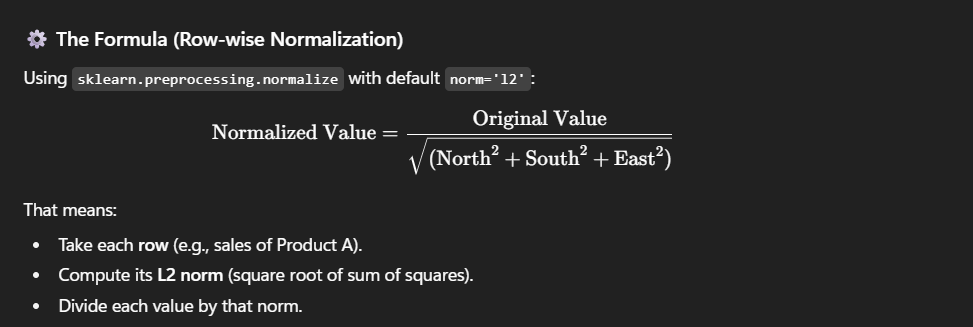

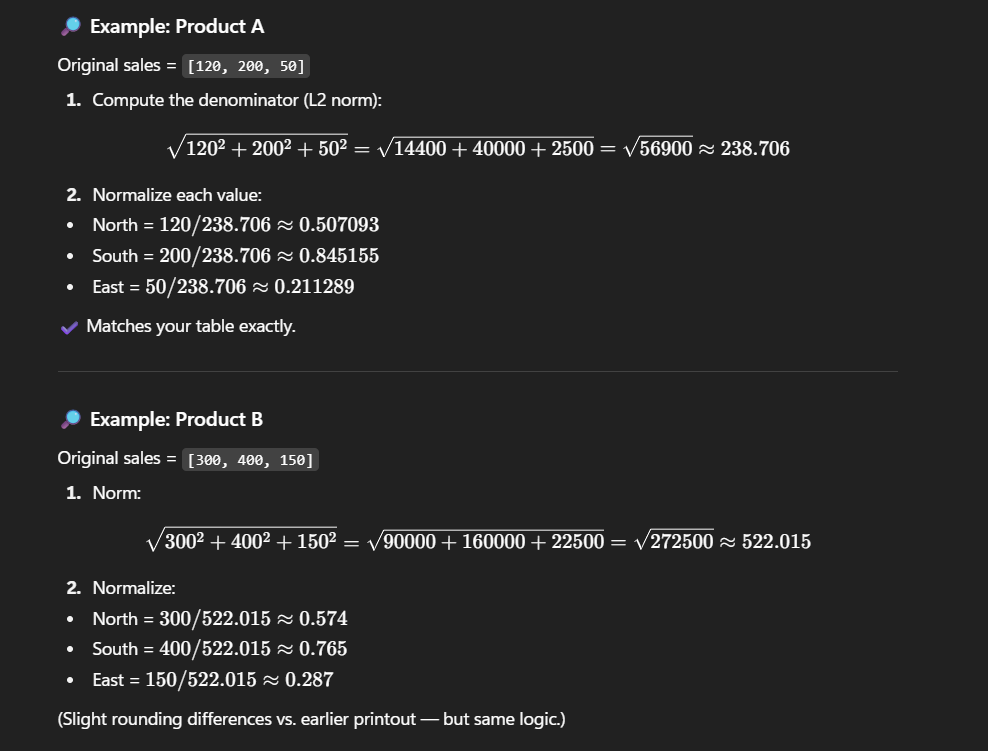

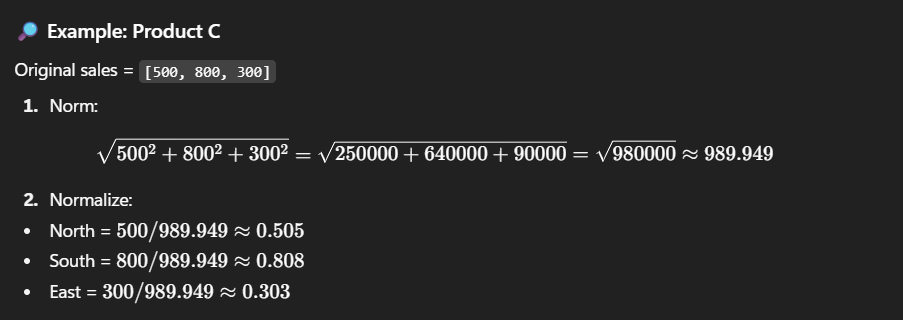

In [94]:
# Case 1: Row-wise Normalization (compare region contribution within each product)

# Normalize row-wise (each product vector → unit length)
row_norm = normalize(df)
row_norm_df = pd.DataFrame(row_norm, columns=df.columns, index=df.index)

print("\nRow-wise Normalized (Region contribution per Product):\n", row_norm_df)


Row-wise Normalized (Region contribution per Product):
               North     South      East
Product A  0.503066  0.838444  0.209611
Product B  0.574696  0.766261  0.287348
Product C  0.505076  0.808122  0.303046


In [ ]:
# Interpretation: For Product A, South contributes the most (0.84), then North (0.50), then East (0.21).

In [ ]:
# Case 2: Column-wise Normalization (Min-Max) (compare products across regions)

# Normalize column-wise (scale 0–1)
col_norm = (df - df.min()) / (df.max() - df.min())
print("\nColumn-wise Normalized (Compare products within region):\n", col_norm)

In [ ]:
# Interpretation:

    Product A is the lowest seller in all regions (0.0).
    Product C is the highest in all regions (1.0).
    Product B lies in the middle (0.33–0.45).

# Takeaway:
    Use row-wise normalization if you want to see regional contribution within each product.
    Use column-wise normalization if you want to see product comparison within each region.